# 9. Generative Adversarial Networks (GAN)

At first, let's recap what a GAN is and how its structure looks like. GANs consist of an overall structure composed of two neural networks, one called **generator** and the other one called **discriminator**. 

The role of the generator is to estimate the probability distribution of the real samples in order to provide generated samples resembling real data. The discriminator, in turn, is trained to estimate the probability that a given sample came from the real data rather than being provided by the generator.

These structures are called generative adversarial networks because the generator and discriminator are trained to compete with each other: *the generator tries to get better at fooling the discriminator, while the discriminator tries to get better at identifying generated samples*.

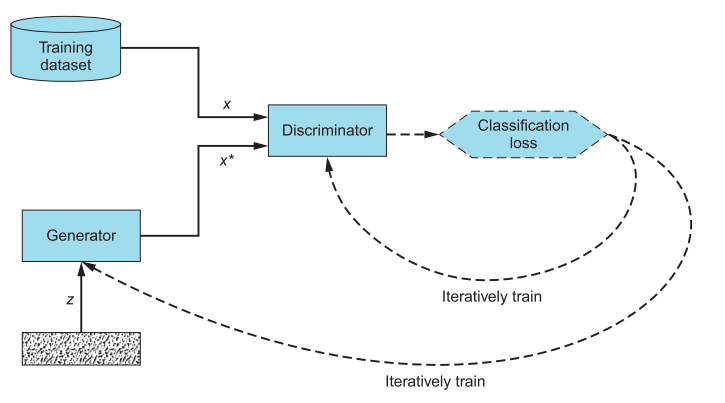

The Generator (G) takes in a random noise vector z and produces a fake example x*. Mathematically, G(z) = x*. The Discriminator (D) is presented either with a real example x or with a fake example x*; for each input, it outputs a value between 0 and 1 indicating the probability that the input is real.

Now let's take a look at the training algorithm:

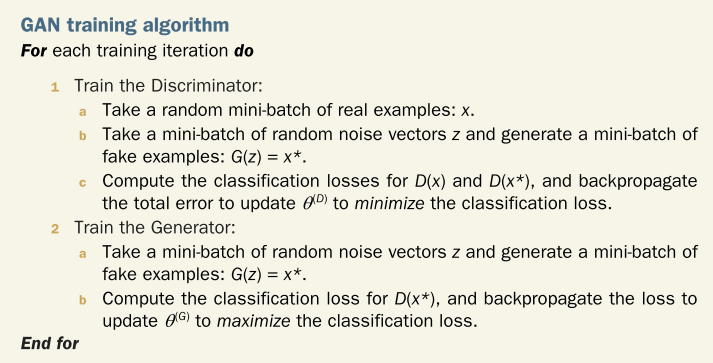

#### Your First GAN!
As a first example to better understand how GANs work you will create a GAN set up to generate the distribution of the sinus curve with a dataset composed of two-dimensional samples (x₁, x₂), with x₁ in the interval from 0 to 2π and x₂ = sin(x₁). For this example you will use the PyTorch library. Later you will also take a look at another machine learing library called keras, to generate handwritten digits.

## 1. Generate the Disribution of a Sinus Function with PyTorch

### <u>Importing libraries</u>

*Important note:* If you have Tensorflow or Keras already installed on your PC, or run into errors down below, please use the following installation:

In [1]:
# %pip install Keras==3.4.1
# %pip install Tensorflow==2.16.2

Else, use this installation:

In [2]:
# %pip install torch

In [3]:
import torch
from torch import nn #Neural Networks

import math
import matplotlib.pyplot as plt

from tqdm import tqdm

import ssl
ssl._create_default_https_context = ssl._create_unverified_context

In [4]:
#random generator seed so that the experiment can be replicated identically on any machine
torch.manual_seed(111)

### <u>Prepare the Training Data</u>
The training data is composed of pairs (x₁, x₂) so that x₂ consists of the value of the sin of x₁ for x₁ in the interval from 0 to 2π.

In [5]:
train_data_length = 1024
train_data = torch.zeros((train_data_length, 2))

# x1 random numbers between 0 and 2pi 
train_data[:, 0] = 2 * math.pi * torch.rand(train_data_length)     

# x2 values of sin(x1) -> ground truth                
train_data[:, 1] = torch.sin(train_data[:, 0])

# labels are required by PyTorch's data loader, but will not be used as GANs make use of unsupervised learning techniques.                                      
train_labels = torch.zeros(train_data_length)

# combine to training set as expected by PyTorch's data loader
train_set = [(train_data[i], train_labels[i]) for i in range(train_data_length)]    

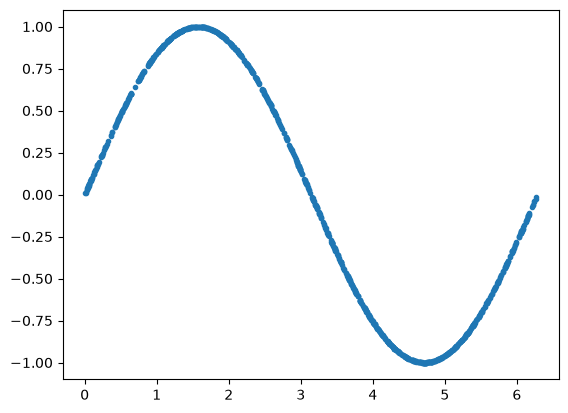

In [6]:
 #Plot training data -> sin
plt.plot(train_data[:, 0], train_data[:, 1], ".")

### <u>Creating a PyTorch data loader</u>
You create a data loader called train_loader, which will shuffle the data from the train_set and return batches of 32 samples that you’ll use to train the neural networks.

In [7]:
# size of samples in batch
batch_size = 32                                         
train_loader = torch.utils.data.DataLoader(
    train_set, batch_size=batch_size, shuffle=True
)

### <u>Implementing the Discriminator</u>
The discriminator is a model with a two-dimensional input and a one-dimensional output. It’ll receive a sample from the real data or from the generator and will provide the probability that the sample belongs to the real training data.

#### **TASK: Discriminator**
Adapt the Discriminator and Generator class in order to create a functional Neural Network with the correct number of neurons.

In [8]:
class Discriminator(nn.Module):                 # In PyTorch, the neural network models are represented by classes that inherit from nn.Module.
    def __init__(self):                         # build model
      
        super().__init__()                      
        self.model = nn.Sequential(
            nn.Linear(2, 256),                  # two-dimensional input with first hidden layer with 256 neurons
            nn.ReLU(),                          # ReLU Activation function
            nn.Dropout(0.3),                    # use dropout after hidden layers to avoid overfitting
            nn.Linear(256, 128),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(128, 64),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(64, 1),                   # last layer outputs one-dimensional value
            nn.Sigmoid(),                       # Sigmoid Activation function in range [0,1]
        )

    # calculate output of the model with input x
    def forward(self, x):                       
        output = self.model(x)
        return output

# instantiate a Discriminator object
discriminator = Discriminator()                 

### <u>Implementing the Generator</u>
In generative adversarial networks, the generator is the model that takes samples from a latent space as its input and generates data resembling the data in the training set. In this case, it’s a model with a two-dimensional input, which will receive random points (z₁, z₂), and a two-dimensional output that must provide (x̃₁, x̃₂) points resembling those from the training data.

In [9]:
class Generator(nn.Module):
    def __init__(self):
        super().__init__()
        self.model = nn.Sequential(
            nn.Linear(2, 16),
            nn.ReLU(),
            nn.Linear(16, 32),
            nn.ReLU(),
            nn.Linear(32, 2), # last layer outputs two-dimensional value   
        )

    def forward(self, x):
        output = self.model(x)
        return output

generator = Generator()

### <U>Setting the training parameters</u>

In [10]:
# learning rate (lr), which you’ll use to adapt the network weights
lr = 0.001                          
# number of epochs (num_epochs), which defines how many repetitions of training using the whole training set will be performed
num_epochs = 300                    
# loss_function to the binary cross-entropy function BCELoss(), which is the loss function that you’ll use to train the models
loss_function = nn.BCELoss()        

The binary cross-entropy function is a suitable loss function for training the discriminator because it considers a binary classification task. It’s also suitable for training the generator since it feeds its output to the discriminator, which provides a binary observable output.

PyTorch implements various weight update rules for model training in torch.optim. Here we’ll use the Adam algorithm to train the discriminator and generator models:

In [11]:
optimizer_discriminator = torch.optim.Adam(discriminator.parameters(), lr=lr)
optimizer_generator = torch.optim.Adam(generator.parameters(), lr=lr)

### <u>Training Loop</u>
For GANs, you update the parameters of the discriminator and the generator at each training iteration. As is generally done for all neural networks, the training process consists of two loops, one for the training epochs and the other for the batches for each epoch. We take a look at the results after a few epoches.

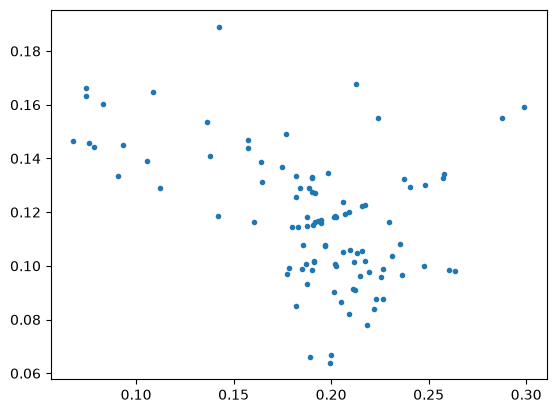

In [12]:
%matplotlib inline
from IPython.display import clear_output

def show_result():
    
    latent_space_samples = torch.randn(100, 2)
    generated_samples = generator(latent_space_samples)                 # create generated samples
    generated_samples = generated_samples.detach()                      # use .detach() to return a tensor from the PyTorch computational graph, which you’ll then use to calculate the gradients
    plt.plot(generated_samples[:, 0], generated_samples[:, 1], ".")     # plot samples
    plt.show()
    
show_result()

Epoch: 250 Loss D.: 0.5683870911598206
Epoch: 250 Loss G.: 0.846261203289032


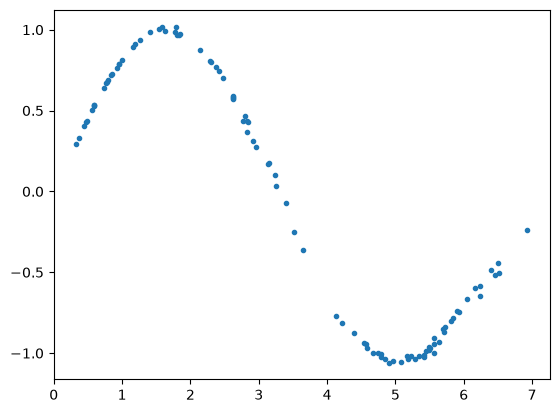

In [13]:
gen_loss = []
dis_loss = []
for epoch in range(num_epochs):
    for n, (real_samples, _) in enumerate(train_loader):                # get the real samples of the current batch from the data loader and assign them to real_samples
        
        # Data for training the discriminator
        real_samples_labels = torch.ones((batch_size, 1))               # create labels with the value 1 for the real samples
        latent_space_samples = torch.randn((batch_size, 2))             # create the generated samples by storing random data in latent_space_samples,
        generated_samples = generator(latent_space_samples)             # then feeding it to the generator to obtain generated_samples
        generated_samples_labels = torch.zeros((batch_size, 1))         # create labels with the value 0 for the fake samples
        all_samples = torch.cat((real_samples, generated_samples))      
        all_samples_labels = torch.cat(                                 
            (real_samples_labels, generated_samples_labels)             # concatenate the real and generated samples and labels and store them in all_samples and all_samples_labels.
        )

        # Training the discriminator
        discriminator.zero_grad()                                       # In PyTorch, it’s necessary to clear the gradients at each training step to avoid accumulating them
        output_discriminator = discriminator(all_samples)               # calculate the output of the discriminator using the training data in all_samples
        loss_discriminator = loss_function(
            output_discriminator, all_samples_labels)                   # calculate the loss function using the output from the model in output_discriminator and the labels in all_samples_labels
        loss_discriminator.backward()                                   # calculate the gradients to update the weights with loss_discriminator.backward()
        optimizer_discriminator.step()                                  # update the discriminator weights by calling optimizer_discriminator.step()

        # Data for training the generator
        latent_space_samples = torch.randn((batch_size, 2))             # create random data to feed your generator

        # Training the generator
        generator.zero_grad()                                               # clear the gradients with .zero_grad()
        generated_samples = generator(latent_space_samples)                 # feed the generator with latent_space_samples 
        output_discriminator_generated = discriminator(generated_samples)   # feed the generator’s output into the discriminator
        loss_generator = loss_function(
            output_discriminator_generated, real_samples_labels             #calculate the loss function using the output of the classification system stored in output_discriminator_generated
        )                                                                   #and the labels in real_samples_labels
        loss_generator.backward()                                           #calculate the gradients
        optimizer_generator.step()                                          #update the generator weights
                                                                            #the discriminator weights are frozen since you created optimizer_generator with its first argument equal to generator.parameters()
        dis_loss.append(loss_discriminator)
        gen_loss.append(loss_generator)
        # Show loss
        if epoch % 50 == 0 and n == batch_size - 1:
            clear_output(wait=True)
            print(f"Epoch: {epoch} Loss D.: {loss_discriminator}")
            print(f"Epoch: {epoch} Loss G.: {loss_generator}")
            show_result()

#### **TASK: Try out the Training Loop**
1. Set different hyperparameters for the training (learning rate, number of epoches, batch size) and analyse how the results are changing.
2. Try different topologies for the neural networks, e.g. change the number of nodes in hidden layers or even remove or add a hole hidden layer. Analyse again the influence on the results.

### <u>Choice of the Frameworks - Pytorch vs. keras</u>
A framework is a kind of toolbox that allows you to create, train, and evaluate complex models, e.g. neural networks. The first part of the exercise was performed with PyTorch, in the next part we will take another Framework called Keras. The right choice of framework can differ from the specific usecases, own preference, hardware infrastructur and operating system.

## 2. Generate handwritten digits with keras

In this next example you will generate handwritten digits like the MNIST dataset with the machine learning library tensorflow and keras.

### <u>Importing libraries</u>
First, we import all the packages and libraries needed to run the model. Notice we also import the MNIST dataset of handwritten digits directly from keras.datasets.

*Important note:* If you have Tensorflow or Keras already installed on your PC, or run into errors down below, please use the following installation:

In [14]:
# %pip install Keras==3.4.1
# %pip install Tensorflow==2.16.2

Else, use this one:

In [15]:
# %pip install tensorflow

In [16]:
import matplotlib.pyplot as plt
import numpy as np

import tensorflow
from keras.datasets import mnist
from keras.layers import Dense, Flatten, Reshape
from keras.layers import LeakyReLU
from keras import Input, Sequential
from keras.optimizers import Adam

### <u>Setting the input dimensions</u>
Second, we specify the input dimensions of our model and dataset. Each image in
MNIST is 28 × 28 pixels with a single channel (because the images are grayscale). The
variable z_dim sets the size of the noise vector, z.

In [17]:
img_rows = 28
img_cols = 28
channels = 1

# Input image dimensions
img_shape = (img_rows, img_cols, channels)

# Size of the noise vector, used as input to the Generator
z_dim = 100

### <u>Implementing a Generator</u>
For simplicity, the Generator is a neural network with only a single hidden layer. It takes in z as input and produces a 28 × 28 × 1 image. In the hidden layer, we use the Leaky ReLU activation function.
At the output layer, we employ the tanh activation function, which scales the output values to the range [–1, 1].

In [18]:
def build_generator(img_shape, z_dim):

    model = Sequential()

    # Fully connected layer
    model.add(Dense(128, input_dim=z_dim)) # Try different number of hidden nodes in the first layer #128

    # Leaky ReLU activation
    model.add(LeakyReLU(alpha=0.01))
    
    ###Add additional hidden layer
    model.add(Dense(128, activation=LeakyReLU(alpha=0.01)))

    # Output layer with tanh activation
    model.add(Dense(28 * 28 * 1, activation='tanh'))

    # Reshape the Generator output to image dimensions
    model.add(Reshape(img_shape))

    return model

### <u>Implementing a Discriminator</u>
The Discriminator takes in a 28 × 28 × 1 image and outputs a probability indicating whether the input is deemed real rather than fake. The Discriminator is represented by a two-layer neural network, with 128 hidden units and a Leaky ReLU activation function at the hidden layer.
Notice that unlike for the Generator, in the following listing we apply the sigmoid activation function at the Discriminator’s output layer. This ensures that our output value will be between 0 and 1, so it can be interpreted as the probability the Generator assigns that the input is real.

In [19]:
def build_discriminator(img_shape):

    model = Sequential()

    # Flatten the input image
    model.add(Flatten(input_shape=img_shape))

    # Fully connected layer
    model.add(Dense(128)) # Try different number of hidden nodes in the first layer

    # Leaky ReLU activation
    model.add(LeakyReLU(alpha=0.01))

    ###Add additional hidden layer
    #model.add(Dense(128, activation=LeakyReLU(alpha=0.01)))
    
    # Output layer with sigmoid activation
    model.add(Dense(1, activation='sigmoid'))

    return model

### <u>Building the model</u>
Notice that in the combined model used to train the Generator, we keep the Discriminator parameters fixed by setting discriminator.trainable to False. Also note that the combined model, in which the Discriminator is set to untrainable, is used to train the Generator only. The Discriminator is trained as an independently compiled model.

In [20]:
def build_gan(generator, discriminator):

    model = Sequential()

    # Combined Generator -> Discriminator model
    model.add(generator)
    model.add(discriminator)

    return model

In [21]:
# Build and compile the Discriminator
discriminator = build_discriminator(img_shape)
discriminator.compile(loss='binary_crossentropy', optimizer=Adam(), metrics=['accuracy'])

# Build the Generator
generator = build_generator(img_shape, z_dim)

# Keep Discriminator’s parameters constant for Generator training
discriminator.trainable = False

# Build and compile GAN model with fixed Discriminator to train the Generator
gan = build_gan(generator, discriminator)
gan.compile(loss='binary_crossentropy', optimizer=Adam())

e:\Programme\conda\envs\AAI\Lib\site-packages\keras\src\layers\reshaping\flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)
e:\Programme\conda\envs\AAI\Lib\site-packages\keras\src\layers\activations\leaky_relu.py:41: UserWarning: Argument `alpha` is deprecated. Use `negative_slope` instead.
  warnings.warn(
e:\Programme\conda\envs\AAI\Lib\site-packages\keras\src\layers\core\dense.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


#### <u>Preparing the training</u>
We get a random mini-batch of MNIST images as real examples and generate a mini-batch of fake
images from random noise vectors z. We then use those to train the Discriminator network while keeping the Generator’s parameters constant. Next, we generate a mini-batch of fake images and use those to train the Generator network while keeping the Discriminator’s parameters fixed. We repeat this for each iteration.

In [22]:
def sample_images(generator, image_grid_rows=4, image_grid_columns=4):

    # Sample random noise
    z = np.random.normal(0, 1, (image_grid_rows * image_grid_columns, z_dim))

    # Generate images from random noise
    gen_imgs = generator.predict(z)

    # Rescale image pixel values to [0, 1]
    gen_imgs = 0.5 * gen_imgs + 0.5

    # Set image grid
    fig, axs = plt.subplots(image_grid_rows, image_grid_columns, figsize=(4, 4), sharey=True, sharex=True)

    cnt = 0
    for i in range(image_grid_rows):
        for j in range(image_grid_columns):
            # Output a grid of images
            axs[i, j].imshow(gen_imgs[cnt, :, :, 0], cmap='gray')
            axs[i, j].axis('off')
            cnt += 1

In [23]:
losses = []
accuracies = []
iteration_checkpoints = []


def train(iterations, batch_size, sample_interval):

    # Load the MNIST dataset
    (X_train, _), (_, _) = mnist.load_data()
    print('MNIST data loaded')

    # Rescale [0, 255] grayscale pixel values to [-1, 1]
    X_train = X_train / 127.5 - 1.0
    X_train = np.expand_dims(X_train, axis=3)

    # Labels for real images: all ones
    real = np.ones((batch_size, 1))

    # Labels for fake images: all zeros
    fake = np.zeros((batch_size, 1))

    for iteration in tqdm(range(iterations)):

        # -------------------------
        #  Train the Discriminator
        # -------------------------

        # Get a random batch of real images
        idx = np.random.randint(0, X_train.shape[0], batch_size)
        imgs = X_train[idx]

        # Generate a batch of fake images
        z = np.random.normal(0, 1, (batch_size, 100))
        gen_imgs = generator.predict(z)

        # Train Discriminator
        d_loss_real = discriminator.train_on_batch(imgs, real)
        d_loss_fake = discriminator.train_on_batch(gen_imgs, fake)
        d_loss, accuracy = 0.5 * np.add(d_loss_real, d_loss_fake)

        # ---------------------
        #  Train the Generator
        # ---------------------

        # Generate a batch of fake images
        z = np.random.normal(0, 1, (batch_size, 100))
        gen_imgs = generator.predict(z)

        # Train Generator
        g_loss = gan.train_on_batch(z, real)

        clear_output(wait=True)

        # Plot the progress
        if (iteration + 1) % sample_interval == 0:

            # Save losses and accuracies so they can be plotted after training
            losses.append((d_loss, g_loss))
            accuracies.append(100.0 * accuracy)
            iteration_checkpoints.append(iteration + 1)

            # Output training progress
            print("%d [D loss: %f, acc.: %.2f%%] [G loss: %f]" %
                  (iteration + 1, d_loss, 100.0 * accuracy, g_loss))

            # Output a sample of generated image
            sample_images(generator)

## 3. Train the GAN and Inspect Output
Note that the `'Discrepancy between trainable weights and collected trainable'` warning from Keras is expected. It is by design: The Generator's trainable parameters are intentionally held constant during Discriminator training, and vice versa.

1000 [D loss: 7.440411, acc.: 5.08%] [G loss: 0.000002]
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step


100%|██████████| 1000/1000 [01:23<00:00, 11.94it/s]


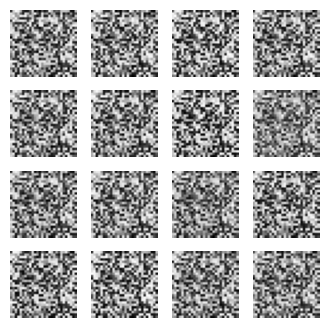

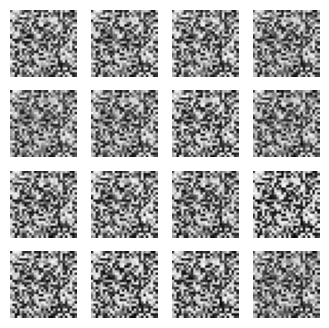

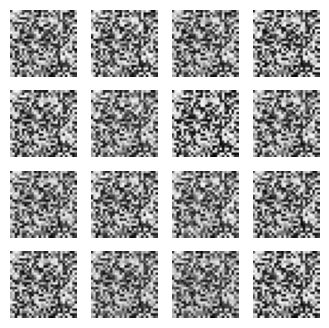

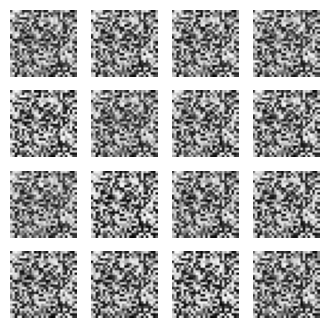

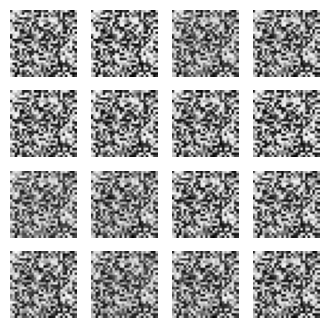

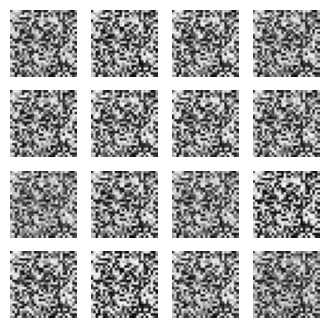

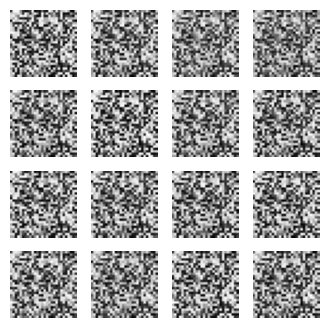

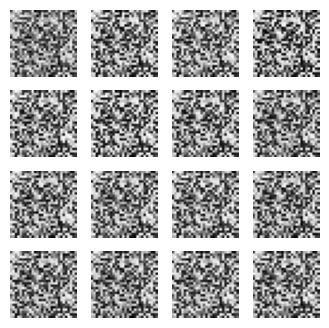

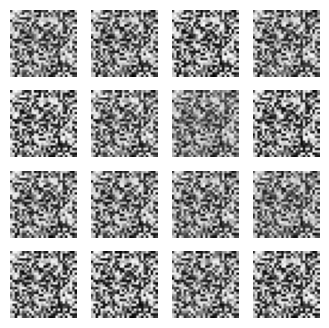

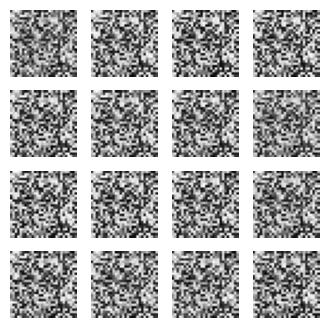

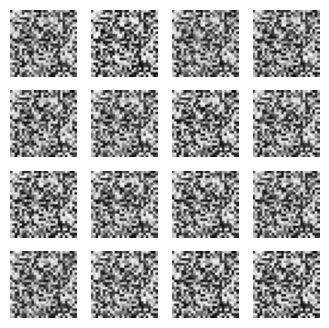

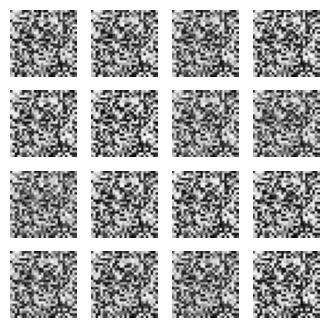

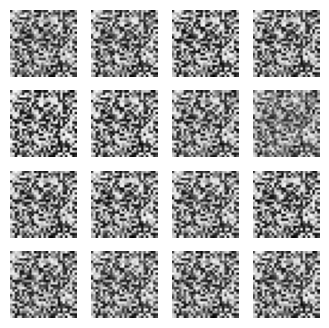

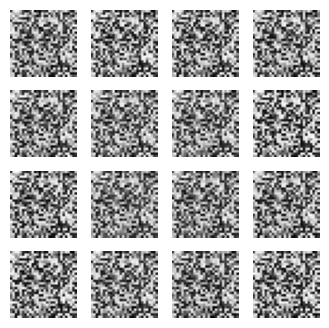

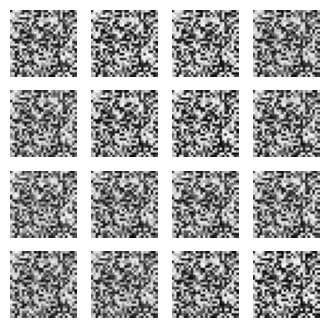

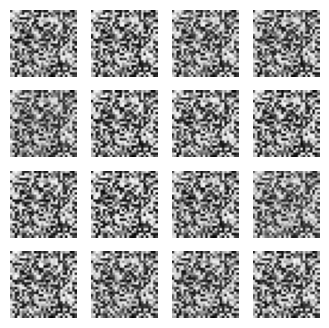

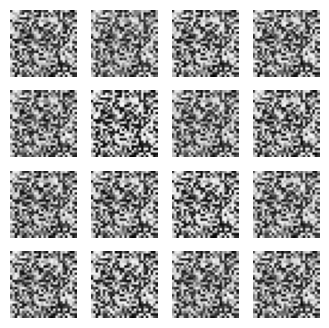

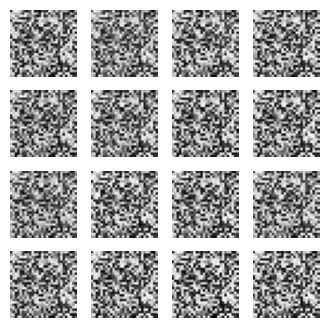

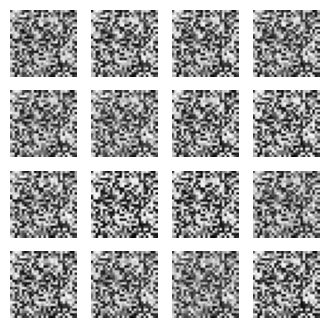

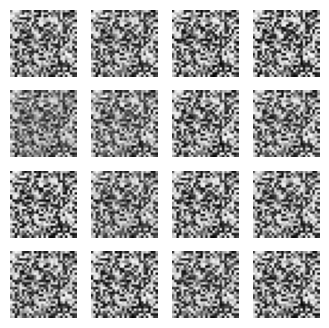

In [24]:
# Set hyperparameters
iterations = 1000
batch_size = 128
sample_interval = 50

# Train the GAN for the specified number of iterations
train(iterations, batch_size, sample_interval)
#Training for these hyperparameters takes a couple of minutes (it: 1000, batch_size: 128)

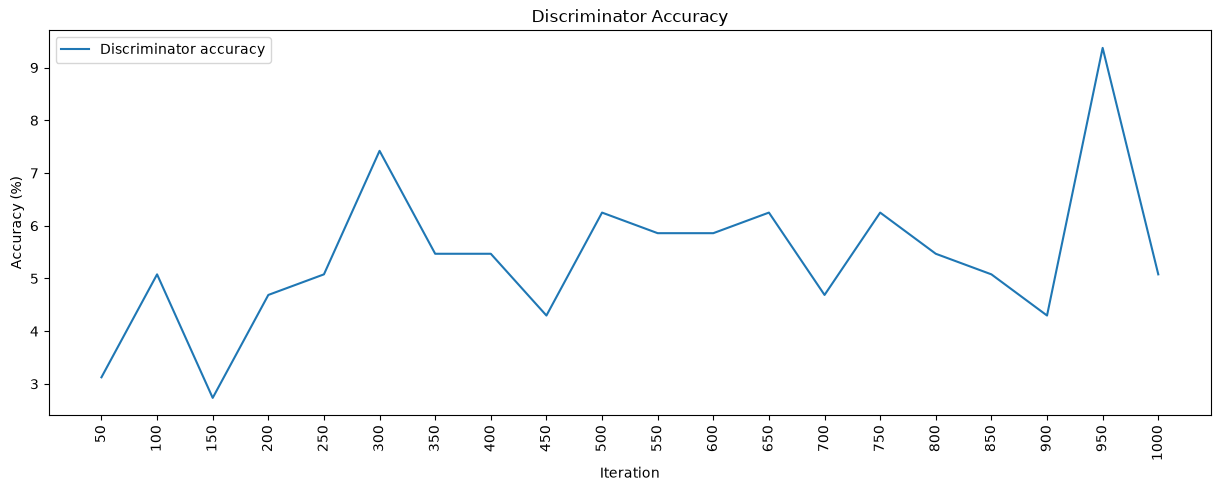

In [25]:
# Plot Discriminator accuracy
plt.figure(figsize=(15, 5))
plt.plot(iteration_checkpoints, np.array(accuracies), label="Discriminator accuracy")

plt.xticks(iteration_checkpoints, rotation=90)
#plt.yticks(range(0, 5, 5))

plt.title("Discriminator Accuracy")
plt.xlabel("Iteration")
plt.ylabel("Accuracy (%)")
plt.legend()
plt.show()

#### **TASK: Try out the Training Loop**
1. Set different hyperparameters for the training (keep the runtime in mind). What is the influence on the results?
2. Try different topologies for the neural networks (see in functions: build_generator, build_discriminator). What is the impact on the results?
3. Try to explain the curve of the Discriminator Accuracy. What does the curve look like until the model is fully trained? (tip: The Discriminator and the Generator work against each other)

The goal of the discriminator is to label real and fake date. At the beginning of the training it is very easy for the discriminator to distinguish between real and fake as the output of the generator is just random noise. Through out the training the performance of the generator improves and looks more and more like the real handwritten digits in the MNIST Dataset. At this point the discriminator can not distinguish between the real and the generated data in some cases. Subsequently the accuracy drops. In a senario where the generator is able to generate perfect imitations of the real data, the accuracy would be 50% as the discriminator can only guess between the two cases.